# Week 5 Ledger Analysis day 1

In [ ]:
import pandas as pd

ledger = pd.read_csv("/content/stock_ledger.csv", parse_dates=["movement_date"])
inv = pd.read_csv("/content/inventory_master.csv")

print("Movement types:")
print(ledger["movement_type"].value_counts().to_string())
print("\nReference types:")
print(ledger["reference_type"].value_counts().to_string())
print("\nDate range:", ledger["movement_date"].min().date(), "to", ledger["movement_date"].max().date())

# Latest running balance for each product and branch
last = (ledger.sort_values(["movement_date", "movement_id"])
        .groupby(["product_id", "branch_id"])
        .tail(1)[["product_id", "branch_id", "running_balance"]])

check = inv.merge(last, on=["product_id", "branch_id"], how="outer", indicator=True)
print("\nMatch status:")
print(check["_merge"].value_counts().to_string())

check["diff"] = check["current_stock"] - check["running_balance"]
print("\nRows where current_stock equals ledger balance:", int((check["diff"] == 0).sum()), "of", len(check))
print("Total current_stock:", f"{check['current_stock'].sum():,.0f}")
print("Total ledger balance:", f"{check['running_balance'].sum():,.0f}")
print("\nSample mismatches:")
print(check.loc[check["diff"] != 0, ["product_id", "branch_id", "current_stock", "running_balance", "diff"]].head(10).to_string(index=False))

Movement types:
movement_type
IN            127611
OUT           107165
ADJUSTMENT      2454

Reference types:
reference_type
PO     127611
SO     107165
ADJ      2454

Date range: 2019-01-01 to 2025-01-28

Match status:
_merge
both          180
left_only       0
right_only      0

Rows where current_stock equals ledger balance: 166 of 180
Total current_stock: 19,303,266
Total ledger balance: 19,304,792

Sample mismatches:
product_id branch_id  current_stock  running_balance  diff
      P002    CHN001         105885           106182  -297
      P004    PUN001         104859           105024  -165
      P011    HYD001         107771           107635   136
      P014    AHM001         105345           105046   299
      P018    PUN001         111530           111382   148
      P021    DEL001         115902           116107  -205
      P025    HYD001         113613           114128  -515
      P026    HYD001         108348           108546  -198
      P026    PUN001         105190       

# Week 5 Ledger Analysis day 2

In [ ]:
import pandas as pd
from pathlib import Path

OUT = Path("/content/week-05/output")
OUT.mkdir(parents=True, exist_ok=True)
DAYS = 2192  # 2019-01-01 to 2024-12-31

ledger = pd.read_csv("/content/stock_ledger.csv", parse_dates=["movement_date"])
products = pd.read_csv("/content/products.csv")
perf = pd.read_csv("/content/product_performance.csv")

ledger["month"] = ledger["movement_date"].dt.to_period("M")

# Last balance in each month for each product and branch
month_end = (ledger.sort_values(["movement_date", "movement_id"])
             .groupby(["product_id", "branch_id", "month"])
             .tail(1)[["product_id", "branch_id", "month", "running_balance"]])

# Full grid of every product-branch-month, carrying balances forward
months = pd.period_range("2019-01", "2024-12", freq="M")
pairs = ledger[["product_id", "branch_id"]].drop_duplicates()
grid = pairs.merge(pd.DataFrame({"month": months}), how="cross")
grid = grid.merge(month_end, on=["product_id", "branch_id", "month"], how="left")
grid = grid.sort_values(["product_id", "branch_id", "month"])
grid["running_balance"] = (grid.groupby(["product_id", "branch_id"])["running_balance"]
                           .ffill().fillna(0))

print("Negative month-end balances:", int((grid["running_balance"] < 0).sum()))

# Value at cost
grid = grid.merge(products[["product_id", "unit_cost"]], on="product_id", how="left")
grid["value"] = grid["running_balance"] * grid["unit_cost"]

monthly_value = grid.groupby("month")["value"].sum()
avg_inventory_value = monthly_value.mean()

# Turnover on average inventory
cogs_total = perf["cogs"].sum()
turnover = cogs_total / avg_inventory_value
print(f"Total COGS: {cogs_total:,.0f}")
print(f"Average inventory value (month-end): {avg_inventory_value:,.0f}")
print(f"Turnover: {turnover:.2f}x")
print(f"Days of inventory: {DAYS / turnover:,.0f}")

# Turnover by product
avg_by_product = (grid.groupby("product_id")["value"].mean()
                  .rename("avg_inventory_value").reset_index())
prod = perf[["product_id", "product_name", "cogs"]].merge(avg_by_product, on="product_id", how="left")
prod["turnover"] = prod["cogs"] / prod["avg_inventory_value"]
prod["days_of_inventory"] = DAYS / prod["turnover"]
prod.sort_values("turnover").to_csv(OUT / "week5_turnover_by_product.csv", index=False)
print("\nSaved:", OUT / "week5_turnover_by_product.csv")
print(prod.sort_values("turnover").head(5).to_string(index=False))

Negative month-end balances: 0
Total COGS: 19,961,848,170
Average inventory value (month-end): 140,733,247,081
Turnover: 0.14x
Days of inventory: 15,454

Saved: /content/week-05/output/week5_turnover_by_product.csv
product_id                 product_name       cogs  avg_inventory_value  turnover  days_of_inventory
      P024           Track Roller TR-60  325762800         4.065735e+08  0.801240        2735.760886
      P023            Idler Wheel IW-55  408820400         5.076450e+08  0.805327        2721.874376
      P014 Transmission Assembly TA-800 3084897500         3.830217e+09  0.805411        2721.593172
      P002      Engine Oil Filter OF-90   20403900         2.470282e+07  0.825974        2653.835190
      P005         Fuel Injector FI-220  285915100         3.460200e+08  0.826297        2652.800663


# Week 5 Ledger Analysis day 3

---



In [ ]:
import pandas as pd
from collections import deque
from pathlib import Path

OUT = Path("/content/week-05/output")
OUT.mkdir(parents=True, exist_ok=True)

ledger = pd.read_csv("/content/stock_ledger.csv", parse_dates=["movement_date"])
ledger = ledger.sort_values(["movement_date", "movement_id"]).reset_index(drop=True)
AS_OF = ledger["movement_date"].max()

# Per-row change in balance, derived from running_balance
ledger["prev_bal"] = ledger.groupby(["product_id", "branch_id"])["running_balance"].shift(1).fillna(0)
ledger["delta"] = ledger["running_balance"] - ledger["prev_bal"]

# Sign check: does the balance change match the recorded quantity?
print("Sign check by movement type:")
for mt, g in ledger.groupby("movement_type"):
    print(f"{mt:12s} rows={len(g):>7,}  delta==qty: {(g['delta'] == g['quantity']).mean():.3f}"
          f"  delta==-qty: {(g['delta'] == -g['quantity']).mean():.3f}")

# FIFO: build lots of stock still on hand, oldest sold first
lots_out = []
for (pid, bid), g in ledger.groupby(["product_id", "branch_id"]):
    q = deque()  # each item: [receipt_date, remaining_qty]
    for d, delta, date in zip(g["delta"], g["delta"], g["movement_date"]):
        if delta > 0:
            q.append([date, delta])
        elif delta < 0:
            need = -delta
            while need > 0 and q:
                take = min(need, q[0][1])
                q[0][1] -= take
                need -= take
                if q[0][1] == 0:
                    q.popleft()
    for date, rem in q:
        lots_out.append((pid, bid, date, rem))

lots = pd.DataFrame(lots_out, columns=["product_id", "branch_id", "lot_date", "qty"])
print("\nUnits on hand from FIFO lots:", f"{lots['qty'].sum():,.0f}",
      "(should match total current_stock, 19,303,266)")

lots["age_days"] = (AS_OF - lots["lot_date"]).dt.days
lots["age_bucket"] = pd.cut(lots["age_days"], bins=[-1, 30, 90, 180, 365, 10**6],
                            labels=["0-30", "31-90", "91-180", "181-365", ">365"])

products = pd.read_csv("/content/products.csv")[["product_id", "product_name", "unit_cost"]]
lots = lots.merge(products, on="product_id", how="left")
lots["value"] = lots["qty"] * lots["unit_cost"]

aging = lots.groupby("age_bucket", observed=False).agg(units=("qty", "sum"), value=("value", "sum"))
aging["pct_of_value"] = (aging["value"] / aging["value"].sum() * 100).round(1)
print(f"\nStock on hand by age, as of {AS_OF.date()}:")
print(aging.to_string())
aging.to_csv(OUT / "week5_aging_buckets.csv")

per_prod = (lots.assign(w=lots["age_days"] * lots["qty"])
            .groupby(["product_id", "product_name"])
            .agg(units=("qty", "sum"), value=("value", "sum"),
                 w=("w", "sum"), oldest_days=("age_days", "max"))
            .reset_index())
per_prod["avg_age_days"] = (per_prod["w"] / per_prod["units"]).round(0)
per_prod.drop(columns="w").sort_values("avg_age_days", ascending=False).to_csv(
    OUT / "week5_aging_by_product.csv", index=False)
print("\nOldest-on-average products:")
print(per_prod.sort_values("avg_age_days", ascending=False).head(5)[
    ["product_name", "avg_age_days", "oldest_days", "value"]].to_string(index=False))

Sign check by movement type:
ADJUSTMENT   rows=  2,454  delta==qty: 0.299  delta==-qty: 0.308
IN           rows=127,611  delta==qty: 0.736  delta==-qty: 0.000
OUT          rows=107,165  delta==qty: 0.002  delta==-qty: 0.800

Units on hand from FIFO lots: 19,304,792 (should match total current_stock, 19,303,266)

Stock on hand by age, as of 2025-01-28:
                 units         value  pct_of_value
age_bucket                                        
0-30          221480.0  3.113008e+09           1.1
31-90         641705.0  9.400465e+09           3.3
91-180        936052.0  1.306604e+10           4.6
181-365      1870067.0  2.767705e+10           9.8
>365        15635488.0  2.280286e+11          81.1

Oldest-on-average products:
                product_name  avg_age_days  oldest_days        value
          Bucket Tooth BT-10         949.0         1858 2.123960e+08
          Alternator ALT-500         938.0         1849 5.597882e+09
         Swing Motor SWM-350         938.0         19

In [ ]:
import pandas as pd

ledger = pd.read_csv("/content/stock_ledger.csv", parse_dates=["movement_date"])

print("Sample movement_ids:", ledger["movement_id"].head(5).tolist())
print("Sorted by id, first 5:", ledger["movement_id"].sort_values().head(5).tolist())

print("\nTotal quantity by type:")
print(ledger.groupby("movement_type")["quantity"].agg(["sum", "min", "max"]).to_string())

# Does the balance chain fit better sorted by id than by date?
for key in [["movement_date", "movement_id"], ["movement_id"]]:
    s = ledger.sort_values(key).copy()
    s["prev"] = s.groupby(["product_id", "branch_id"])["running_balance"].shift(1).fillna(0)
    s["delta"] = s["running_balance"] - s["prev"]
    ins = s[s["movement_type"] == "IN"]
    outs = s[s["movement_type"] == "OUT"]
    print(key, "| IN match:", round((ins["delta"] == ins["quantity"]).mean(), 3),
          "| OUT match:", round((outs["delta"] == -outs["quantity"]).mean(), 3))

Sample movement_ids: ['MOV-OUT-184742', 'MOV-OUT-208422', 'MOV-IN-111128', 'MOV-OUT-159140', 'MOV-OUT-173693']
Sorted by id, first 5: ['MOV-ADJ-0', 'MOV-ADJ-1', 'MOV-ADJ-10', 'MOV-ADJ-100', 'MOV-ADJ-1000']

Total quantity by type:
                    sum  min  max
movement_type                    
ADJUSTMENT        66990    5   50
IN             20397795   20  300
OUT             1124832    1   20
['movement_date', 'movement_id'] | IN match: 0.736 | OUT match: 0.8
['movement_id'] | IN match: 0.076 | OUT match: 0.077


In [ ]:
import pandas as pd

ledger = pd.read_csv("/content/stock_ledger.csv", parse_dates=["movement_date"])
print("Sample dates:", ledger["movement_date"].head(3).tolist())

s = ledger.sort_values(["movement_date", "movement_id"]).copy()
s["prev"] = s.groupby(["product_id", "branch_id"])["running_balance"].shift(1).fillna(0)
s["delta"] = s["running_balance"] - s["prev"]
s["ok"] = (((s["movement_type"] == "IN") & (s["delta"] == s["quantity"])) |
           ((s["movement_type"] == "OUT") & (s["delta"] == -s["quantity"])) |
           (s["movement_type"] == "ADJUSTMENT"))

bad = s[~s["ok"]]
print("Mismatched IN/OUT rows:", len(bad))

per_day = s.groupby(["product_id", "branch_id", "movement_date"])["movement_id"].transform("size")
print("Share of mismatches on a day with several movements:",
      round((per_day[bad.index] > 1).mean(), 3))
print("Share of all rows on a day with several movements:",
      round((per_day > 1).mean(), 3))
print("\nMismatches by year:")
print(bad.groupby(bad["movement_date"].dt.year).size().to_string())
print("\nFirst mismatches:")
print(bad.head(5)[["movement_id", "product_id", "branch_id", "movement_type",
                   "movement_date", "quantity", "running_balance", "delta"]].to_string(index=False))

Sample dates: [Timestamp('2019-01-03 00:00:00'), Timestamp('2019-01-05 00:00:00'), Timestamp('2019-01-23 00:00:00')]
Mismatched IN/OUT rows: 55041
Share of mismatches on a day with several movements: 0.795
Share of all rows on a day with several movements: 0.528

Mismatches by year:
movement_date
2019    9118
2020    9536
2021    9189
2022    8776
2023    9408
2024    8675
2025     339

First mismatches:
   movement_id product_id branch_id movement_type movement_date  quantity  running_balance  delta
MOV-OUT-184737       P020    AHM001           OUT    2019-01-03         3              139  139.0
MOV-OUT-184738       P025    AHM001           OUT    2019-01-03        15              150  150.0
MOV-OUT-184741       P007    AHM001           OUT    2019-01-03         6              140  140.0
MOV-OUT-184742       P001    AHM001           OUT    2019-01-03         8              228  228.0
MOV-OUT-184744       P011    AHM001           OUT    2019-01-03         3              208  208.0


# Week 5 Ledger Analysis day 3

---






In [ ]:
import pandas as pd
from pathlib import Path

OUT = Path("/content/week-05/output")
DAYS = 2192

prod = pd.read_csv(OUT / "week5_turnover_by_product.csv")
products = pd.read_csv("/content/products.csv")[["product_id", "category"]]
prod = prod.merge(products, on="product_id", how="left")

cat = prod.groupby("category").agg(
    products=("product_id", "size"),
    cogs=("cogs", "sum"),
    avg_inventory=("avg_inventory_value", "sum"))
cat["turnover"] = cat["cogs"] / cat["avg_inventory"]
cat["days_of_inventory"] = DAYS / cat["turnover"]
cat = cat.sort_values("turnover")
cat.to_csv(OUT / "week5_turnover_by_category.csv")
print(cat.round(2).to_string())

# Sales header columns, needed for turnover by branch
print("\nSales header columns:",
      pd.read_csv("/content/sales_orders_header.csv", nrows=0).columns.tolist())

               products        cogs  avg_inventory  turnover  days_of_inventory
category                                                                       
Transmission          1  3084897500   3.830217e+09      0.81            2721.59
Brakes                1    82749600   9.957772e+07      0.83            2637.77
Belts                 1    14584960   1.738031e+07      0.84            2612.12
Cabin                 1   255348800   3.036938e+08      0.84            2607.01
Seals                 2    53753230   6.380976e+07      0.84            2602.09
Lubricants            1     8071920   9.577912e+06      0.84            2600.97
Undercarriage         4  2584992100   3.065035e+09      0.84            2599.06
Filters               2    57864780   6.844893e+07      0.85            2592.94
Attachments           1    15427840   1.803549e+07      0.86            2562.50
Engine                4  6714586500   7.847255e+09      0.86            2561.76
Electrical            3   985792650   1.

# Week 5 Ledger Analysis day 4

---



In [ ]:
import pandas as pd
from pathlib import Path

OUT = Path("/content/week-05/output")
OUT.mkdir(parents=True, exist_ok=True)
DAYS = 2192

products = pd.read_csv("/content/products.csv")[["product_id", "unit_cost"]]
headers = pd.read_csv("/content/sales_orders_header.csv", usecols=["so_id", "branch_id"])
lines = pd.read_csv("/content/sales_orders_lines.csv")

# COGS by branch: sales lines joined to their order header
lines = lines[lines["quantity"] > 0].merge(headers, on="so_id", how="left")
lines = lines.merge(products, on="product_id", how="left")
lines["cogs"] = lines["quantity"] * lines["unit_cost"]
cogs_branch = lines.groupby("branch_id")["cogs"].sum().rename("cogs")
print("Lines with no branch:", int(lines["branch_id"].isna().sum()))

# Average month-end inventory value by branch
ledger = pd.read_csv("/content/stock_ledger.csv", parse_dates=["movement_date"])
ledger["month"] = ledger["movement_date"].dt.to_period("M")
month_end = (ledger.sort_values(["movement_date", "movement_id"])
             .groupby(["product_id", "branch_id", "month"]).tail(1)
             [["product_id", "branch_id", "month", "running_balance"]])

months = pd.period_range("2019-01", "2024-12", freq="M")
pairs = ledger[["product_id", "branch_id"]].drop_duplicates()
grid = (pairs.merge(pd.DataFrame({"month": months}), how="cross")
        .merge(month_end, on=["product_id", "branch_id", "month"], how="left")
        .sort_values(["product_id", "branch_id", "month"]))
grid["running_balance"] = (grid.groupby(["product_id", "branch_id"])["running_balance"]
                           .ffill().fillna(0))
grid = grid.merge(products, on="product_id", how="left")
grid["value"] = grid["running_balance"] * grid["unit_cost"]

avg_branch = (grid.groupby(["branch_id", "month"])["value"].sum()
              .groupby("branch_id").mean().rename("avg_inventory"))

br = pd.concat([cogs_branch, avg_branch], axis=1)
br["turnover"] = br["cogs"] / br["avg_inventory"]
br["days_of_inventory"] = DAYS / br["turnover"]
br = br.sort_values("turnover")
br.to_csv(OUT / "week5_turnover_by_branch.csv")
print(br.round(2).to_string())

Lines with no branch: 0
                 cogs  avg_inventory  turnover  days_of_inventory
branch_id                                                        
HYD001     2706527690   2.383933e+10      0.11           19307.33
PUN001     2934731060   2.404956e+10      0.12           17963.02
DEL001     3034255720   2.372661e+10      0.13           17140.52
AHM001     3458891070   2.311112e+10      0.15           14646.19
KOL001     3755788160   2.217074e+10      0.17           12939.57
CHN001     4071654470   2.383588e+10      0.17           12832.19


In [ ]:
import pandas as pd
from pathlib import Path

OUT = Path("/content/week-05/output")
DAYS = 2192

ledger = pd.read_csv("/content/stock_ledger.csv", parse_dates=["movement_date"])
products = pd.read_csv("/content/products.csv")[["product_id", "unit_cost", "category"]]
ledger["month"] = ledger["movement_date"].dt.to_period("M")

month_end = (ledger.sort_values(["movement_date", "movement_id"])
             .groupby(["product_id", "branch_id", "month"]).tail(1)
             [["product_id", "branch_id", "month", "running_balance"]])
months = pd.period_range("2019-01", "2024-12", freq="M")
pairs = ledger[["product_id", "branch_id"]].drop_duplicates()
grid = (pairs.merge(pd.DataFrame({"month": months}), how="cross")
        .merge(month_end, on=["product_id", "branch_id", "month"], how="left")
        .sort_values(["product_id", "branch_id", "month"]))
grid["running_balance"] = (grid.groupby(["product_id", "branch_id"])["running_balance"]
                           .ffill().fillna(0))
grid = grid.merge(products, on="product_id", how="left")
grid["value"] = grid["running_balance"] * grid["unit_cost"]

# Total value per product per month across all branches, then averaged over months
prod_avg = (grid.groupby(["product_id", "month"])["value"].sum()
            .groupby("product_id").mean().rename("avg_inventory_value"))
print("Sum of product averages:", f"{prod_avg.sum():,.0f}",
      "(should be about 140,733,247,081)")

prod = pd.read_csv(OUT / "week5_turnover_by_product.csv")[["product_id", "product_name", "cogs"]]
prod = prod.merge(prod_avg, on="product_id", how="left").merge(
    products[["product_id", "category"]], on="product_id", how="left")
prod["turnover"] = prod["cogs"] / prod["avg_inventory_value"]
prod["days_of_inventory"] = DAYS / prod["turnover"]
prod.sort_values("turnover").to_csv(OUT / "week5_turnover_by_product_corrected.csv", index=False)

cat = prod.groupby("category").agg(
    products=("product_id", "size"),
    cogs=("cogs", "sum"),
    avg_inventory=("avg_inventory_value", "sum"))
cat["turnover"] = cat["cogs"] / cat["avg_inventory"]
cat["days_of_inventory"] = DAYS / cat["turnover"]
cat.sort_values("turnover").to_csv(OUT / "week5_turnover_by_category_corrected.csv")
print(cat.sort_values("turnover").round(2).to_string())

Sum of product averages: 140,733,247,081 (should be about 140,733,247,081)
               products        cogs  avg_inventory  turnover  days_of_inventory
category                                                                       
Transmission          1  3084897500   2.298130e+10      0.13           16329.56
Brakes                1    82749600   5.974663e+08      0.14           15826.62
Belts                 1    14584960   1.042819e+08      0.14           15672.71
Cabin                 1   255348800   1.822163e+09      0.14           15642.06
Seals                 2    53753230   3.828586e+08      0.14           15612.57
Lubricants            1     8071920   5.746747e+07      0.14           15605.79
Undercarriage         4  2584992100   1.839021e+10      0.14           15594.38
Filters               2    57864780   4.106936e+08      0.14           15557.66
Attachments           1    15427840   1.082129e+08      0.14           15374.98
Engine                4  6714586500   4.70835

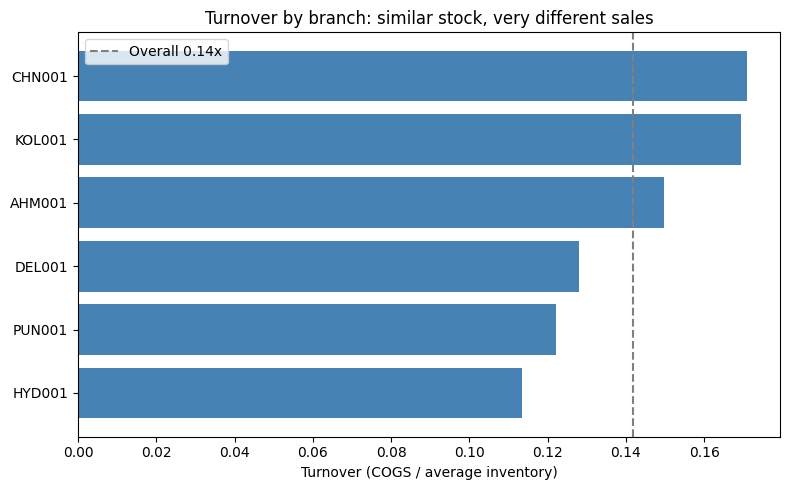

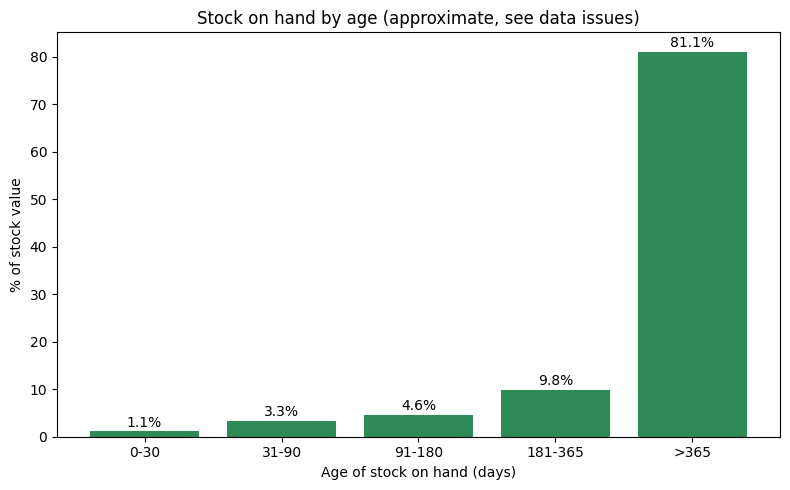

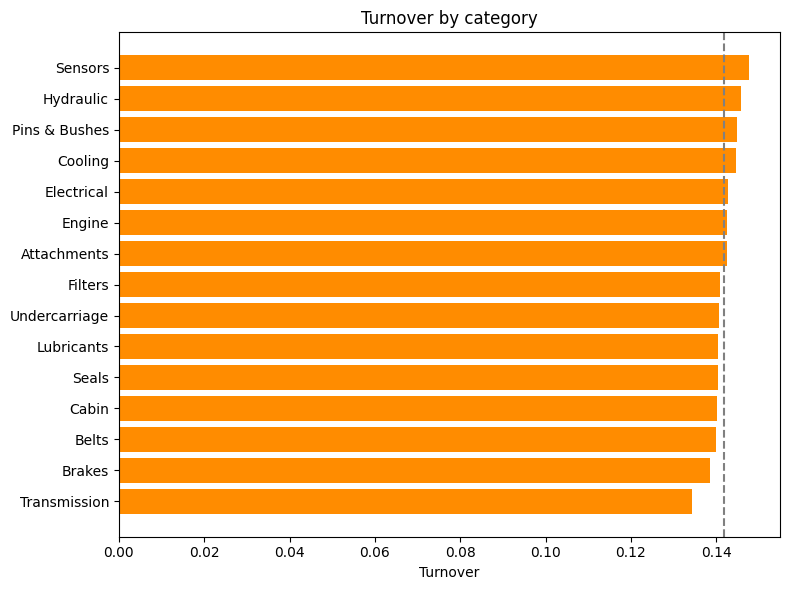

                                                       value
Overall turnover (x)                                    0.14
Days of inventory (2,192-day period)                   15454
Average inventory value (month-end)           140733247081.0
Total COGS                                       19961848170
Lowest-turnover branch                        HYD001 (0.11x)
Highest-turnover branch                       CHN001 (0.17x)
Stock value older than 365 days (%, approx.)            81.1
Products with average age over 365 days                   30
Total products                                            30

Saved to /content/week-05/output


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("/content/week-05/output")
OUT.mkdir(parents=True, exist_ok=True)

br = pd.read_csv(OUT / "week5_turnover_by_branch.csv", index_col="branch_id")
aging = pd.read_csv(OUT / "week5_aging_buckets.csv", index_col="age_bucket")
cat = pd.read_csv(OUT / "week5_turnover_by_category_corrected.csv", index_col="category")
prod = pd.read_csv(OUT / "week5_turnover_by_product_corrected.csv")
aging_prod = pd.read_csv(OUT / "week5_aging_by_product.csv")

overall_turnover = br["cogs"].sum() / br["avg_inventory"].sum()

# Chart 1: turnover by branch
br_sorted = br.sort_values("turnover")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(br_sorted.index, br_sorted["turnover"], color="steelblue")
ax.axvline(overall_turnover, linestyle="--", color="grey", label=f"Overall {overall_turnover:.2f}x")
ax.set_xlabel("Turnover (COGS / average inventory)")
ax.set_title("Turnover by branch: similar stock, very different sales")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "week5_chart1_turnover_by_branch.png", dpi=150)
plt.show()

# Chart 2: stock value by age bucket
order = ["0-30", "31-90", "91-180", "181-365", ">365"]
ag = aging.reindex(order)
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(ag.index, ag["pct_of_value"], color="seagreen")
for i, v in enumerate(ag["pct_of_value"]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_ylabel("% of stock value")
ax.set_xlabel("Age of stock on hand (days)")
ax.set_title("Stock on hand by age (approximate, see data issues)")
fig.tight_layout()
fig.savefig(OUT / "week5_chart2_aging.png", dpi=150)
plt.show()

# Chart 3: turnover by category
cat_sorted = cat.sort_values("turnover")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(cat_sorted.index, cat_sorted["turnover"], color="darkorange")
ax.axvline(overall_turnover, linestyle="--", color="grey")
ax.set_xlabel("Turnover")
ax.set_title("Turnover by category")
fig.tight_layout()
fig.savefig(OUT / "week5_chart3_turnover_by_category.png", dpi=150)
plt.show()

# KPI summary
over_365 = ag.loc[">365", "pct_of_value"]
kpis = {
    "Overall turnover (x)": round(overall_turnover, 2),
    "Days of inventory (2,192-day period)": round(2192 / overall_turnover),
    "Average inventory value (month-end)": round(br["avg_inventory"].sum(), 0),
    "Total COGS": round(br["cogs"].sum(), 0),
    "Lowest-turnover branch": f"{br_sorted.index[0]} ({br_sorted['turnover'].iloc[0]:.2f}x)",
    "Highest-turnover branch": f"{br_sorted.index[-1]} ({br_sorted['turnover'].iloc[-1]:.2f}x)",
    "Stock value older than 365 days (%, approx.)": over_365,
    "Products with average age over 365 days": int((aging_prod["avg_age_days"] > 365).sum()),
    "Total products": len(aging_prod),
}
kpi_df = pd.Series(kpis, name="value").to_frame()
kpi_df.to_csv(OUT / "week5_kpis.csv")
print(kpi_df.to_string())
print("\nSaved to", OUT)

In [ ]:
import shutil
from google.colab import files

shutil.make_archive("/content/week05_outputs", "zip", "/content/week-05/output")
files.download("/content/week05_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>